# Day 3 — Hysteresis / Motion-History Analysis

This notebook analyzes the low-speed ascending/descending hysteresis experiment.

Main questions:
1. Is the dataset complete and sampled correctly?
2. At the same commanded velocity, does measured friction torque depend on whether speed was approached from below or above?
3. Is branch separation repeatable across the three repeats?
4. How large is the effect relative to repeat-to-repeat variability?
5. Is it concentrated near zero speed or present across the full ±0.2 rad/s range?

The notebook automatically loads the newest `day3_hysteresis_raw_*.csv` file.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

DATA_DIR = Path('/home/uexpj/ros2_ws/day3_hysteresis_data')
OUT_DIR = Path('/home/uexpj/ros2_ws/day3_hysteresis_analysis')
OUT_DIR.mkdir(parents=True, exist_ok=True)

files = sorted(DATA_DIR.glob('day3_hysteresis_raw_*.csv'), key=lambda p: p.stat().st_mtime)
if not files:
    raise FileNotFoundError(f'No hysteresis CSV found in {DATA_DIR}')
CSV_FILE = files[-1]
print('Loading:', CSV_FILE)
df = pd.read_csv(CSV_FILE)
print('Shape:', df.shape)
df.head()

Loading: /home/uexpj/ros2_ws/day3_hysteresis_data/day3_hysteresis_raw_20261007_124208.csv
Shape: (547308, 11)


,wall_time_s,ros_time_s,repeat,sequence_name,point,previous_command_velocity_rad_s,command_velocity_rad_s,measured_position_rad,measured_velocity_rad_s,torque_raw_per_mille,torque_Nm
0,1.791348e+09,1.791348e+09,1,positive_up,1,0.0,0.0,7.562789,-0.001361,-4.0,-0.008888
1,1.791348e+09,1.791348e+09,1,positive_up,1,0.0,0.0,7.562783,0.004503,-4.0,-0.008888
2,1.791348e+09,1.791348e+09,1,positive_up,1,0.0,0.0,7.562789,0.002723,-8.0,-0.017776
3,1.791348e+09,1.791348e+09,1,positive_up,1,0.0,0.0,7.562789,-0.003979,-8.0,-0.017776
4,1.791348e+09,1.791348e+09,1,positive_up,1,0.0,0.0,7.562801,-0.000733,-8.0,-0.017776


## 1. Dataset integrity

In [2]:
required = [
    'wall_time_s','ros_time_s','repeat','sequence_name','point',
    'previous_command_velocity_rad_s','command_velocity_rad_s',
    'measured_position_rad','measured_velocity_rad_s',
    'torque_raw_per_mille','torque_Nm'
]
print('Missing required columns:', [x for x in required if x not in df.columns])
print('\nMissing values:')
print(df[required].isna().sum())
print('\nRows per repeat:')
print(df['repeat'].value_counts().sort_index())
print('\nRows per sequence:')
print(df['sequence_name'].value_counts())
print('\nUnique points per repeat/sequence:')
print(df.groupby(['repeat','sequence_name'])['point'].nunique().unstack())
print('\nCommands by sequence:')
for name,g in df.groupby('sequence_name'):
    print(name, sorted(g['command_velocity_rad_s'].unique()))


Missing required columns: []

Missing values:
wall_time_s                        0
ros_time_s                         0
repeat                             0
sequence_name                      0
point                              0
previous_command_velocity_rad_s    0
command_velocity_rad_s             0
measured_position_rad              0
measured_velocity_rad_s            0
torque_raw_per_mille               0
torque_Nm                          0
dtype: int64

Rows per repeat:
repeat
1    182436
2    182440
3    182432
Name: count, dtype: int64

Rows per sequence:
sequence_name
positive_up      136829
negative_up      136829
negative_down    136828
positive_down    136822
Name: count, dtype: int64

Unique points per repeat/sequence:
sequence_name  negative_down  negative_up  positive_down  positive_up
repeat                                                               
1                         17           17             17           17
2                         17           17    

## 2. Sampling-rate check

In [3]:
tmp = df[['ros_time_s','repeat','sequence_name','point']].copy()
same_block = (
    tmp['repeat'].eq(tmp['repeat'].shift()) &
    tmp['sequence_name'].eq(tmp['sequence_name'].shift()) &
    tmp['point'].eq(tmp['point'].shift())
)
dt = tmp['ros_time_s'].diff()
dt = dt[same_block & (dt > 0) & (dt < 0.1)]
print(f'Median dt: {dt.median():.9f} s')
print(f'Median rate: {1/dt.median():.3f} Hz')
print(f'Min dt: {dt.min():.9f} s')
print(f'Max dt: {dt.max():.9f} s')

Median dt: 0.005000114 s
Median rate: 199.995 Hz
Min dt: 0.002827168 s
Max dt: 0.007173777 s


## 3. Per-block steady-state summary

In [4]:
block = (
    df.groupby([
        'repeat','sequence_name','point',
        'previous_command_velocity_rad_s','command_velocity_rad_s'
    ], as_index=False)
    .agg(
        n=('torque_Nm','size'),
        mean_velocity=('measured_velocity_rad_s','mean'),
        std_velocity=('measured_velocity_rad_s','std'),
        mean_torque=('torque_Nm','mean'),
        std_torque=('torque_Nm','std'),
        position_start=('measured_position_rad','first'),
        position_end=('measured_position_rad','last'),
    )
)
block['position_change_rad'] = block['position_end'] - block['position_start']
block['velocity_error_rad_s'] = block['mean_velocity'] - block['command_velocity_rad_s']
block['relative_velocity_std'] = block['std_velocity'] / block['command_velocity_rad_s'].abs().replace(0,np.nan)
block.to_csv(OUT_DIR/'per_block_summary.csv', index=False)
print(block.to_string(index=False))

 repeat sequence_name  point  previous_command_velocity_rad_s  command_velocity_rad_s    n  mean_velocity  std_velocity  mean_torque  std_torque  position_start  position_end  position_change_rad  velocity_error_rad_s  relative_velocity_std
      1 negative_down      1                           0.0000                  0.0000 1601       0.000214      0.003780     0.030898    0.010627       34.207946     34.207946             0.000000              0.000214                    NaN
      1 negative_down      2                           0.0000                 -0.0025 4000      -0.002449      0.003526    -0.030951    0.016114       34.193577     34.145131            -0.048446              0.000051               1.410479
      1 negative_down      3                          -0.0025                 -0.0050 4000      -0.004924      0.003845    -0.021560    0.011999       34.105601     34.006917            -0.098684              0.000076               0.769020
      1 negative_down      4        

## 4. Velocity tracking and low-speed shaft travel

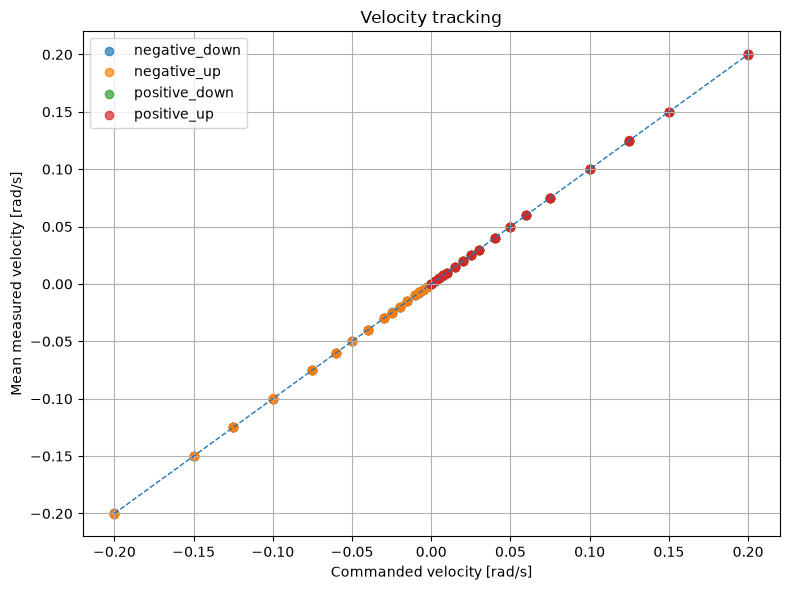

 repeat sequence_name  command_velocity_rad_s  mean_velocity  std_velocity  position_change_rad
      1 negative_down                 -0.0025      -0.002449      0.003526            -0.048446
      1 negative_down                 -0.0050      -0.004924      0.003845            -0.098684
      1 negative_down                 -0.0075      -0.007428      0.004240            -0.148269
      1 negative_down                 -0.0100      -0.009919      0.004596            -0.198998
      1 negative_down                 -0.0150      -0.014939      0.005172            -0.224446
      1 negative_down                 -0.0200      -0.019944      0.005567            -0.298982
      1   negative_up                 -0.0200      -0.019896      0.005729            -0.298287
      1   negative_up                 -0.0150      -0.014889      0.005092            -0.224584
      1   negative_up                 -0.0100      -0.010018      0.004586            -0.198483
      1   negative_up                 -0

In [5]:
fig,ax=plt.subplots(figsize=(8,6))
for seq,g in block.groupby('sequence_name'):
    ax.scatter(g['command_velocity_rad_s'],g['mean_velocity'],label=seq,alpha=0.7)
lims=[min(block['command_velocity_rad_s'].min(),block['mean_velocity'].min()),
      max(block['command_velocity_rad_s'].max(),block['mean_velocity'].max())]
ax.plot(lims,lims,'--',linewidth=1)
ax.set_xlabel('Commanded velocity [rad/s]')
ax.set_ylabel('Mean measured velocity [rad/s]')
ax.set_title('Velocity tracking')
ax.grid(True); ax.legend(); fig.tight_layout()
fig.savefig(OUT_DIR/'01_velocity_tracking.png',dpi=160)
plt.show()

low=block[(block['command_velocity_rad_s']!=0)&(block['command_velocity_rad_s'].abs()<=0.02)]
print(low[['repeat','sequence_name','command_velocity_rad_s','mean_velocity','std_velocity','position_change_rad']].to_string(index=False))

## 5. Build matched hysteresis branches

For positive velocity:
- `positive_up` = increasing speed
- `positive_down` = decreasing speed

For negative velocity:
- `negative_down` = increasing speed magnitude
- `negative_up` = decreasing speed magnitude

Zero-command points are excluded from the dynamic branch comparison.

In [6]:
branch_map={
    'positive_up':'increasing_speed',
    'positive_down':'decreasing_speed',
    'negative_down':'increasing_speed',
    'negative_up':'decreasing_speed',
}
b=block[block['command_velocity_rad_s']!=0].copy()
b['branch']=b['sequence_name'].map(branch_map)
b['direction']=np.where(b['command_velocity_rad_s']>0,'positive','negative')
b['speed_abs']=b['command_velocity_rad_s'].abs()
branch_means=(
    b.groupby(['repeat','direction','speed_abs','branch'],as_index=False)
     .agg(mean_torque=('mean_torque','mean'),
          std_torque_within_block=('std_torque','mean'),
          mean_velocity=('mean_velocity','mean'))
)
print(branch_means.head(30).to_string(index=False))

 repeat direction  speed_abs           branch  mean_torque  std_torque_within_block  mean_velocity
      1  negative     0.0025 decreasing_speed    -0.021571                 0.014544      -0.002376
      1  negative     0.0025 increasing_speed    -0.030951                 0.016114      -0.002449
      1  negative     0.0050 decreasing_speed    -0.020362                 0.011916      -0.005006
      1  negative     0.0050 increasing_speed    -0.021560                 0.011999      -0.004924
      1  negative     0.0075 decreasing_speed    -0.020753                 0.013518      -0.007416
      1  negative     0.0075 increasing_speed    -0.019885                 0.012474      -0.007428
      1  negative     0.0100 decreasing_speed    -0.020065                 0.013290      -0.010018
      1  negative     0.0100 increasing_speed    -0.020409                 0.012985      -0.009919
      1  negative     0.0150 decreasing_speed    -0.019242                 0.013607      -0.014889
      1  n

## 6. Matched increasing-vs-decreasing differences

In [7]:
wide=(branch_means.pivot_table(
    index=['repeat','direction','speed_abs'],
    columns='branch',values='mean_torque').reset_index())
wide.columns.name=None
wide['delta_tau_signed_Nm']=wide['increasing_speed']-wide['decreasing_speed']
wide['delta_tau_abs_Nm']=wide['delta_tau_signed_Nm'].abs()
wide['mag_increasing_Nm']=wide['increasing_speed'].abs()
wide['mag_decreasing_Nm']=wide['decreasing_speed'].abs()
wide['delta_magnitude_Nm']=wide['mag_increasing_Nm']-wide['mag_decreasing_Nm']
wide.to_csv(OUT_DIR/'matched_branch_differences.csv',index=False)
print(wide.to_string(index=False))

 repeat direction  speed_abs  decreasing_speed  increasing_speed  delta_tau_signed_Nm  delta_tau_abs_Nm  mag_increasing_Nm  mag_decreasing_Nm  delta_magnitude_Nm
      1  negative     0.0025         -0.021571         -0.030951            -0.009381          0.009381           0.030951           0.021571            0.009381
      1  negative     0.0050         -0.020362         -0.021560            -0.001197          0.001197           0.021560           0.020362            0.001197
      1  negative     0.0075         -0.020753         -0.019885             0.000869          0.000869           0.019885           0.020753           -0.000869
      1  negative     0.0100         -0.020065         -0.020409            -0.000343          0.000343           0.020409           0.020065            0.000343
      1  negative     0.0150         -0.019242         -0.019771            -0.000529          0.000529           0.019771           0.019242            0.000529
      1  negative     0.0200

## 7. Mean hysteresis branches

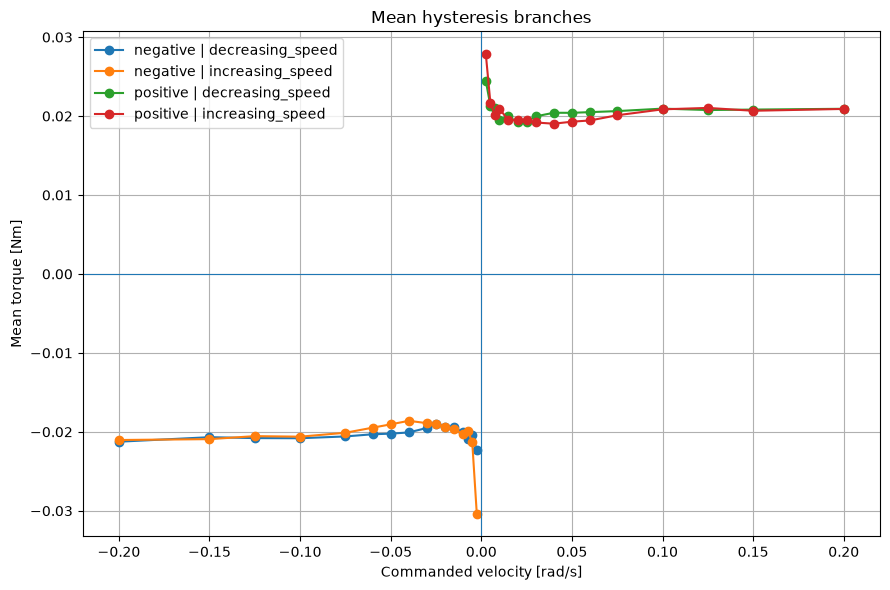

In [8]:
fig,ax=plt.subplots(figsize=(9,6))
for (direction,branch),g in branch_means.groupby(['direction','branch']):
    gg=g.groupby('speed_abs',as_index=False).agg(torque=('mean_torque','mean'))
    x=gg['speed_abs'].to_numpy()
    if direction=='negative': x=-x
    ax.plot(x,gg['torque'],marker='o',label=f'{direction} | {branch}')
ax.axhline(0,linewidth=.8); ax.axvline(0,linewidth=.8)
ax.set_xlabel('Commanded velocity [rad/s]')
ax.set_ylabel('Mean torque [Nm]')
ax.set_title('Mean hysteresis branches')
ax.grid(True); ax.legend(); fig.tight_layout()
fig.savefig(OUT_DIR/'02_hysteresis_branches.png',dpi=160)
plt.show()

## 8. Hysteresis gap versus speed

direction  speed_abs  mean_delta_tau  std_delta_tau  mean_abs_gap  mean_delta_magnitude  std_delta_magnitude
 negative     0.0025       -0.008052       0.001884      0.008052              0.008052             0.001884
 negative     0.0050       -0.000898       0.000388      0.000898              0.000898             0.000388
 negative     0.0075        0.001014       0.000160      0.001014             -0.001014             0.000160
 negative     0.0100       -0.000256       0.000276      0.000292              0.000256             0.000276
 negative     0.0150       -0.000186       0.000325      0.000264              0.000186             0.000325
 negative     0.0200        0.000027       0.000189      0.000135             -0.000027             0.000189
 negative     0.0250       -0.000076       0.000150      0.000140              0.000076             0.000150
 negative     0.0300        0.000602       0.000112      0.000602             -0.000602             0.000112
 negative     0.040

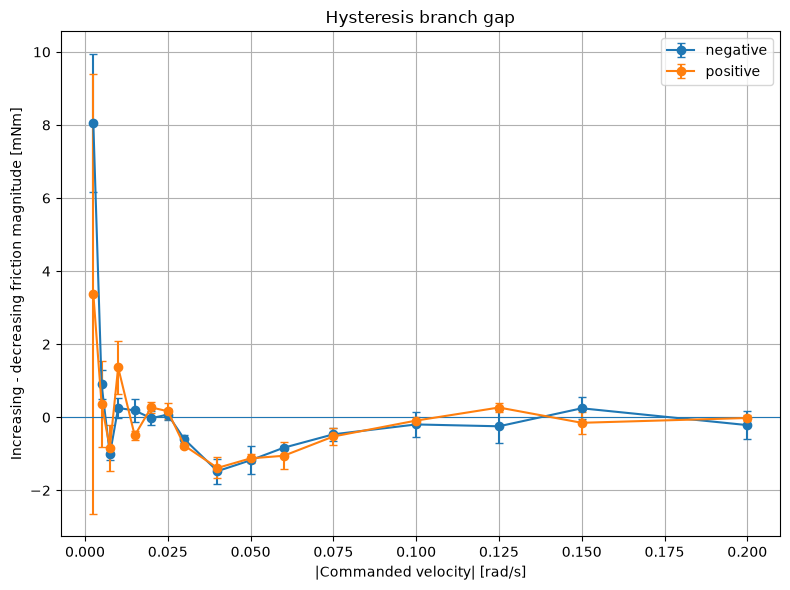

In [9]:
gap_stats=(wide.groupby(['direction','speed_abs'],as_index=False)
    .agg(mean_delta_tau=('delta_tau_signed_Nm','mean'),
         std_delta_tau=('delta_tau_signed_Nm','std'),
         mean_abs_gap=('delta_tau_abs_Nm','mean'),
         mean_delta_magnitude=('delta_magnitude_Nm','mean'),
         std_delta_magnitude=('delta_magnitude_Nm','std')))
gap_stats.to_csv(OUT_DIR/'hysteresis_gap_by_speed.csv',index=False)
print(gap_stats.to_string(index=False))

fig,ax=plt.subplots(figsize=(8,6))
for direction,g in gap_stats.groupby('direction'):
    ax.errorbar(g['speed_abs'],g['mean_delta_magnitude']*1000,
                yerr=g['std_delta_magnitude']*1000,marker='o',capsize=3,label=direction)
ax.axhline(0,linewidth=.8)
ax.set_xlabel('|Commanded velocity| [rad/s]')
ax.set_ylabel('Increasing - decreasing friction magnitude [mNm]')
ax.set_title('Hysteresis branch gap')
ax.grid(True); ax.legend(); fig.tight_layout()
fig.savefig(OUT_DIR/'03_hysteresis_gap_vs_speed.png',dpi=160)
plt.show()

## 9. Repeatability across the three runs

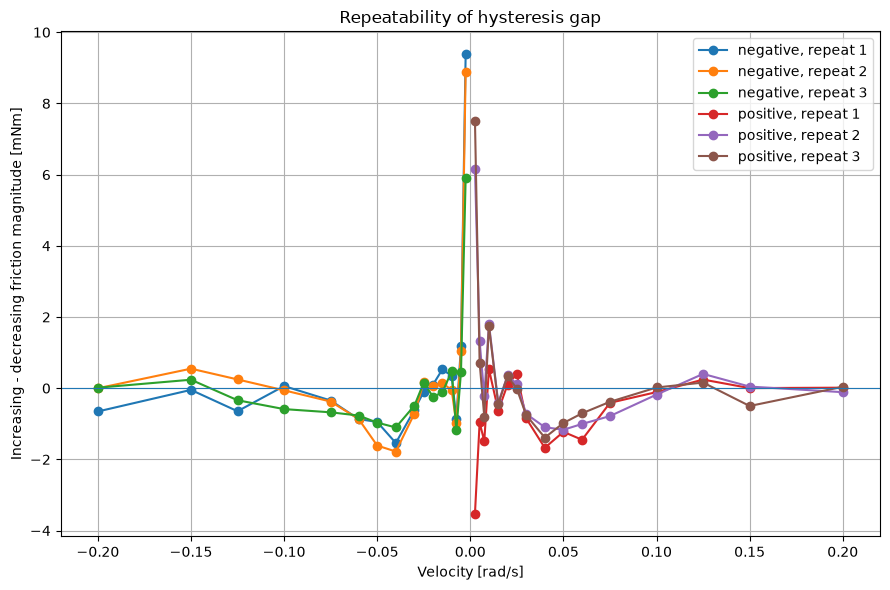

In [10]:
fig,ax=plt.subplots(figsize=(9,6))
for (direction,repeat),g in wide.groupby(['direction','repeat']):
    x=g['speed_abs'].to_numpy()
    if direction=='negative': x=-x
    ax.plot(x,g['delta_magnitude_Nm']*1000,marker='o',label=f'{direction}, repeat {repeat}')
ax.axhline(0,linewidth=.8)
ax.set_xlabel('Velocity [rad/s]')
ax.set_ylabel('Increasing - decreasing friction magnitude [mNm]')
ax.set_title('Repeatability of hysteresis gap')
ax.grid(True); ax.legend(); fig.tight_layout()
fig.savefig(OUT_DIR/'04_hysteresis_gap_repeats.png',dpi=160)
plt.show()

## 10. Engineering effect ratio

We compare the mean branch gap to repeat-to-repeat variation:

`effect ratio = |mean branch gap| / std(branch gap across repeats)`

This is not a formal hypothesis test. With only three repeats it is an engineering diagnostic.


In [11]:
effect=gap_stats.copy()
effect['engineering_effect_ratio']=effect['mean_delta_magnitude'].abs()/effect['std_delta_magnitude'].replace(0,np.nan)
effect.to_csv(OUT_DIR/'hysteresis_effect_ratio.csv',index=False)
print(effect[['direction','speed_abs','mean_delta_magnitude','std_delta_magnitude','engineering_effect_ratio']].to_string(index=False))

direction  speed_abs  mean_delta_magnitude  std_delta_magnitude  engineering_effect_ratio
 negative     0.0025              0.008052             0.001884                  4.274533
 negative     0.0050              0.000898             0.000388                  2.313299
 negative     0.0075             -0.001014             0.000160                  6.322164
 negative     0.0100              0.000256             0.000276                  0.926561
 negative     0.0150              0.000186             0.000325                  0.571290
 negative     0.0200             -0.000027             0.000189                  0.143452
 negative     0.0250              0.000076             0.000150                  0.506498
 negative     0.0300             -0.000602             0.000112                  5.373315
 negative     0.0400             -0.001474             0.000343                  4.295934
 negative     0.0500             -0.001176             0.000377                  3.117665
 negative 

## 11. Approximate integrated branch separation

We integrate the absolute difference between increasing- and decreasing-speed friction-magnitude branches over speed. This is a compact branch-separation metric; it is **not mechanical energy per cycle**, because the integration variable is velocity, not displacement.

In [12]:
areas=[]
for direction,g in gap_stats.groupby('direction'):
    g=g.sort_values('speed_abs')
    area=np.trapezoid(np.abs(g['mean_delta_magnitude'].to_numpy()),g['speed_abs'].to_numpy())
    areas.append({'direction':direction,'area_Nm_rad_per_s':area})
areas=pd.DataFrame(areas)
areas.to_csv(OUT_DIR/'hysteresis_area_summary.csv',index=False)
print(areas.to_string(index=False))

direction  area_Nm_rad_per_s
 negative           0.000094
 positive           0.000087


## 12. Is hysteresis concentrated near zero?

In [13]:
def region(v):
    if v<=0.02: return '<=0.02'
    if v<=0.05: return '0.02-0.05'
    if v<=0.10: return '0.05-0.10'
    return '0.10-0.20'
rt=wide.copy(); rt['speed_region']=rt['speed_abs'].map(region)
region_summary=(rt.groupby(['direction','speed_region'],as_index=False)
    .agg(mean_abs_gap_Nm=('delta_tau_abs_Nm','mean'),
         mean_delta_magnitude_Nm=('delta_magnitude_Nm','mean'),
         std_delta_magnitude_Nm=('delta_magnitude_Nm','std'),
         n=('delta_magnitude_Nm','size')))
region_summary.to_csv(OUT_DIR/'hysteresis_region_summary.csv',index=False)
print(region_summary.to_string(index=False))

direction speed_region  mean_abs_gap_Nm  mean_delta_magnitude_Nm  std_delta_magnitude_Nm  n
 negative    0.02-0.05         0.000848                -0.000794                0.000660 12
 negative    0.05-0.10         0.000512                -0.000499                0.000340  9
 negative    0.10-0.20         0.000304                -0.000072                0.000409  9
 negative       <=0.02         0.001776                 0.001392                0.003193 18
 positive    0.02-0.05         0.000866                -0.000780                0.000635 12
 positive    0.05-0.10         0.000561                -0.000556                0.000474  9
 positive    0.10-0.20         0.000168                 0.000032                0.000250  9
 positive       <=0.02         0.001617                 0.000674                0.002570 18


## 13. Zero-command history

Zero is analyzed separately because static/holding friction is not part of the moving branch comparison.

 repeat sequence_name  previous_command_velocity_rad_s  mean_velocity  mean_torque  std_torque
      1 negative_down                           0.0000       0.000214     0.030898    0.010627
      1   negative_up                          -0.0025      -0.000048    -0.024692    0.004850
      1 positive_down                           0.0025       0.000041     0.030925    0.011037
      1   positive_up                           0.0000       0.000014    -0.014889    0.004260
      2 negative_down                           0.0000      -0.000032     0.023878    0.005172
      2   negative_up                          -0.0025       0.000119    -0.033529    0.009621
      2 positive_down                           0.0025       0.000073     0.024183    0.005419
      2   positive_up                           0.0000      -0.000037    -0.024828    0.004687
      3 negative_down                           0.0000       0.000094     0.030704    0.009877
      3   negative_up                          -0.

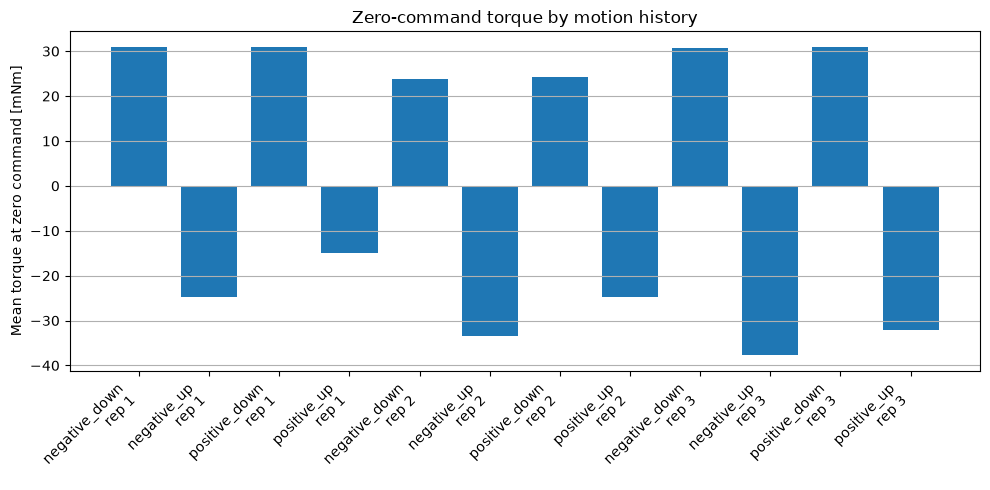

In [14]:
zero=block[block['command_velocity_rad_s']==0].copy()
zero.to_csv(OUT_DIR/'zero_command_history.csv',index=False)
print(zero[['repeat','sequence_name','previous_command_velocity_rad_s','mean_velocity','mean_torque','std_torque']].to_string(index=False))
fig,ax=plt.subplots(figsize=(10,5))
labels=zero['sequence_name'].astype(str)+'\nrep '+zero['repeat'].astype(str)
ax.bar(np.arange(len(zero)),zero['mean_torque']*1000)
ax.set_xticks(np.arange(len(zero))); ax.set_xticklabels(labels,rotation=45,ha='right')
ax.set_ylabel('Mean torque at zero command [mNm]')
ax.set_title('Zero-command torque by motion history')
ax.grid(True,axis='y'); fig.tight_layout()
fig.savefig(OUT_DIR/'05_zero_command_history.png',dpi=160)
plt.show()


## 14. Final numerical summary

After running this cell, send me its printed output plus the four plots:
- `02_hysteresis_branches.png`
- `03_hysteresis_gap_vs_speed.png`
- `04_hysteresis_gap_repeats.png`
- `05_zero_command_history.png`

That is enough to judge whether hysteresis is meaningful and whether the next experiment should be a torque-controlled breakaway/static-friction test.

In [15]:
print('='*72)
print('DAY 3 HYSTERESIS ANALYSIS — FINAL SUMMARY')
print('='*72)
print('\nDataset')
print('Rows:',len(df))
print('Repeats:',sorted(df['repeat'].unique()))
print('Sequences:',sorted(df['sequence_name'].unique()))
print(f'Median sample rate: {1/dt.median():.3f} Hz')

print('\nMean absolute branch gap by direction')
for direction,g in wide.groupby('direction'):
    print(f'{direction:>8}: {g["delta_tau_abs_Nm"].mean()*1000:.4f} mNm')

print('\nMaximum mean branch separation by direction')
for direction,g in gap_stats.groupby('direction'):
    idx=g['mean_delta_magnitude'].abs().idxmax(); r=g.loc[idx]
    print(f'{direction:>8}: {r["mean_delta_magnitude"]*1000:+.4f} mNm at |w|={r["speed_abs"]:.4f} rad/s (repeat std {r["std_delta_magnitude"]*1000:.4f} mNm)')

print('\nRegion summary [mNm]')
display_region=region_summary.copy()
for c in ['mean_abs_gap_Nm','mean_delta_magnitude_Nm','std_delta_magnitude_Nm']:
    display_region[c]*=1000
print(display_region.to_string(index=False))

print('\nApproximate integrated branch separation')
print(areas.to_string(index=False))

print('\nLargest engineering effect ratios')
cols=['direction','speed_abs','mean_delta_magnitude','std_delta_magnitude','engineering_effect_ratio']
print(effect[cols].sort_values('engineering_effect_ratio',ascending=False).head(10).to_string(index=False))

print('\nZero-command history [mNm]')
z=zero[['repeat','sequence_name','previous_command_velocity_rad_s','mean_torque']].copy()
z['mean_torque']*=1000
print(z.to_string(index=False))

print('\nSaved analysis outputs to:')
print(OUT_DIR)
print('='*72)


DAY 3 HYSTERESIS ANALYSIS — FINAL SUMMARY

Dataset
Rows: 547308
Repeats: [np.int64(1), np.int64(2), np.int64(3)]
Sequences: ['negative_down', 'negative_up', 'positive_down', 'positive_up']
Median sample rate: 199.995 Hz

Mean absolute branch gap by direction
negative: 1.0310 mNm
positive: 0.9596 mNm

Maximum mean branch separation by direction
negative: +8.0517 mNm at |w|=0.0025 rad/s (repeat std 1.8837 mNm)
positive: +3.3823 mNm at |w|=0.0025 rad/s (repeat std 6.0168 mNm)

Region summary [mNm]
direction speed_region  mean_abs_gap_Nm  mean_delta_magnitude_Nm  std_delta_magnitude_Nm  n
 negative    0.02-0.05         0.848055                -0.793977                0.660293 12
 negative    0.05-0.10         0.511783                -0.498513                0.340046  9
 negative    0.10-0.20         0.304029                -0.071570                0.408611  9
 negative       <=0.02         1.775937                 1.391755                3.193011 18
 positive    0.02-0.05         0.866298 

# Interpretation and conclusions

## 1. Are all three repeats and all four branch sequences complete?

Yes. The dataset contains **547,308 samples**, all **3 repeats**, and all four intended sequences:

- `negative_down`
- `negative_up`
- `positive_down`
- `positive_up`

The median sample rate is **199.995 Hz**, consistent with the intended ~200 Hz acquisition.

## 2. Is velocity tracking adequate, including at ±0.0025 rad/s?

Yes. The measured-velocity-versus-command plot lies essentially on the \(y=x\) line across the full \(\pm 0.2\ \mathrm{rad/s}\) range, including the lowest nonzero commands.

This means the observed branch differences are not explained by one branch simply failing to reach the requested steady-state velocity.

## 3. Do increasing- and decreasing-speed branches visibly separate?

Yes, but the separation is strongly velocity dependent.

The largest separation occurs extremely close to zero. A smaller but systematic branch difference is also visible over approximately

\[
0.02 \lesssim |\omega| \lesssim 0.075\ \mathrm{rad/s}.
\]

Above roughly \(0.1\ \mathrm{rad/s}\), the increasing- and decreasing-speed branches are much closer together.

## 4. Is the separation consistent across all three repeats?

Partly.

For the **negative direction at \(|\omega|=0.0025\ \mathrm{rad/s}\)**, all three repeats show a large positive branch gap. The mean separation is approximately

\[
8.05\ \mathrm{mNm}
\]

with a repeat standard deviation of approximately

\[
1.88\ \mathrm{mNm}.
\]

This is strong evidence of repeatable history dependence.

The corresponding positive-direction point is less repeatable. Its mean gap is approximately **3.38 mNm**, but its repeat standard deviation is approximately **6.02 mNm**, and individual repeats do not preserve the same sign. Therefore a unique positive-side hysteresis value at \(0.0025\ \mathrm{rad/s}\) should not be claimed.

Outside the extreme near-zero point, both directions show a smaller and more systematic branch difference, particularly around \(0.03{-}0.075\ \mathrm{rad/s}\).

## 5. At which speed range is separation largest?

The largest branch separation occurs at the smallest tested nonzero speed:

\[
|\omega| = 0.0025\ \mathrm{rad/s}.
\]

The maximum mean gap is:

- **negative direction:** approximately **+8.05 mNm**
- **positive direction:** approximately **+3.38 mNm**, but with poor repeatability

The region summary also shows that the average absolute branch gap is largest for

\[
|\omega| \leq 0.02\ \mathrm{rad/s}.
\]

The hysteresis effect decreases substantially as speed increases.

## 6. Is the branch gap large relative to repeat-to-repeat variability?

For the negative-direction \(0.0025\ \mathrm{rad/s}\) point, yes. The mean gap of approximately **8.05 mNm** is much larger than its **1.88 mNm** repeat standard deviation.

For the positive-direction \(0.0025\ \mathrm{rad/s}\) point, no. The repeat variation is larger than the mean gap, so the exact branch ordering at that point is not robust.

In the intermediate low-speed region, the branch gaps are typically on the order of **0.5–1.5 mNm** and are smaller but more systematic across direction and repeat.

## 7. Is the effect symmetric between positive and negative rotation?

Not perfectly.

The extreme near-zero effect is substantially stronger and more repeatable in the negative direction.

However, away from the first velocity point, the two directions show similar trends. For example, in the \(0.02{-}0.05\ \mathrm{rad/s}\) region, the mean signed branch differences are approximately:

- negative: **-0.794 mNm**
- positive: **-0.780 mNm**

This suggests that the smaller intermediate-speed hysteresis behavior is approximately symmetric, while the very-near-zero regime contains additional directional/state dependence.

## 8. Does zero-command torque retain a strong dependence on previous motion?

Yes, very strongly.

The zero-command measurements retain both the **sign** and a substantial magnitude related to the preceding motion history. Across the repeats, zero-command torque is roughly:

- after one direction of motion: **+24 to +31 mNm**
- after the opposite direction: approximately **-15 to -34 mNm**

Therefore there is no single history-independent value that can represent friction torque at zero velocity.

This is strong evidence that the near-zero regime contains an internal friction/contact state or other memory-dependent behavior.

## 9. Is a memoryless Coulomb + viscous + Stribeck model adequate for the intended compensation task?

It remains a useful **nominal sliding-friction model**, but it is not a complete model of the near-zero regime.

The Day 2 and Day 3 results support keeping a model of the form

\[
	au_f(\omega)
=
	au_c\,\mathrm{sgn}(\omega)
+b\omega
+	au_{\mathrm{Stribeck}}(\omega)
\]

for ordinary motion.

However, the hysteresis experiment shows that very close to zero velocity the torque is not uniquely determined by instantaneous velocity. In that region, a more complete description would require an additional history/state variable.

For the thesis, the practical approach is therefore:

1. retain Coulomb + viscous + Stribeck as the nominal compensation model;
2. document that it represents the sliding regime;
3. treat the near-zero/pre-sliding regime separately;
4. validate later whether the nominal model is sufficient for the required impedance-control performance.

## 10. Should the next experiment be a torque-controlled breakaway/static-friction test?

Yes.

The current experiment shows that the near-zero regime is strongly history dependent, so the next useful measurement is a **torque-controlled breakaway experiment**.

The experiment should start from rest and gradually increase commanded torque until sustained motion begins. It should be repeated in both directions and under controlled pre-history conditions.

The pre-history must be standardized because this hysteresis experiment demonstrates that the state at rest depends strongly on the preceding direction of motion.

A suitable protocol is:

1. apply a defined conditioning motion;
2. command zero velocity/torque and wait a fixed duration;
3. apply a slow torque ramp;
4. detect the first sustained motion;
5. record the corresponding breakaway torque;
6. repeat for both torque directions and both conditioning histories.

This will characterize static/breakaway friction directly and will also provide the first dedicated validation of torque-control operation.

---

# Overall conclusion

The hysteresis experiment confirms that the motor cannot be described by a purely memoryless friction-versus-velocity relation in the immediate vicinity of zero velocity.

The strongest history dependence occurs below approximately **0.02 rad/s**, with a repeatable negative-direction branch gap of about **8 mNm** at \(0.0025\ \mathrm{rad/s}\). A smaller, approximately symmetric hysteresis effect persists over roughly **0.02–0.075 rad/s**, while the branch separation becomes small above approximately **0.1 rad/s**.

The zero-command measurements show an even stronger dependence on previous motion, with residual torque changing sign and reaching magnitudes comparable to or larger than the previously identified Coulomb friction level.

The resulting modeling decision is to keep the Coulomb + viscous + Stribeck formulation as the nominal sliding-friction model, while explicitly documenting its limitation near zero velocity. The next experiment will use torque control to characterize static/breakaway friction under controlled motion-history conditions.
